# Limites globais versus trajetórias observadas

## Resumo e plano

Este experimento pergunta se coeficientes sorteados em intervalos finitos e algumas trajetórias aparentemente regulares substituem a checagem de sensibilidade global do gerador Shao--Wu. Testamos seis casos: quadrado autorregressivo, soma de dois lags, produto entre lags, choque gaussiano raro, uma rejeição conservadora e uma interação multiplicativa entre duas séries com duas posições possíveis para tanh. O objetivo é distinguir **risco real do mecanismo**, **o que uma simulação finita observa** e **o que nosso cálculo de limites consegue demonstrar**.

A condição (5.2) do [Teorema 5.1 de Shao e Wu (2007, p. 11)](https://arxiv.org/pdf/math/0611029#page=11) compara **todos os pares de históricos**, usando os mesmos valores futuros de inovação. O cálculo de limites da AST está em src/tsfmxai/generators/shao_wu.py. As equações específicas abaixo são exemplos didáticos deste experimento, não exemplos atribuídos aos autores. Os casos 1–4 são testes de estresse da ideia de dispensar limites globais, não amostras do gerador Shao--Wu selecionado. No caso 6 distinguimos a regra do amostrador atual (tanh em cada lag do produto) da alternativa com tanh ao redor do produto completo.

**Sequência:** (1) coeficiente limitado com quadrado que cresce; (2) coeficientes menores que 1 cuja soma cresce, e o efeito de GMC_SCALE; (3) produto entre dois lags que parece inofensivo numa trajetória curta; (4) cauda gaussiana difícil de observar em uma amostra pequena; (5) rejeição conservadora de um mecanismo que admite uma prova de contração mais precisa; (6) série exógena estável multiplicando o passado de outra série, com contração em média apesar do limite global infinito.

In [1]:
from pathlib import Path
import hashlib
import json
import math
import platform
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(parent for parent in (Path.cwd(), *Path.cwd().parents)
            if (parent / "src" / "tsfmxai").is_dir())
sys.path.insert(0, str(ROOT / "src"))

from tsfmxai.generators import (
    RandomTreeConfig, ShaoWuConfig, build_shao_wu_mechanism, global_expression_bounds,
    saturate_product_lags, saturate_product_outputs
)
from tsfmxai.representations import (
    Add, Lag, MechanismBinding, Multiply, Parameter, Tanh, to_bound_formula
)

ROOT_SEED = 20261020
EXPLOSION_LIMIT = 1_000_000.0

def quadratic_path(initial, innovations, coefficient=0.5):
    values = [float(initial)]
    for shock in innovations:
        following = coefficient * values[-1] ** 2 + float(shock)
        values.append(following)
        if not np.isfinite(following) or abs(following) >= EXPLOSION_LIMIT:
            break
    return np.asarray(values)

def two_lag_path(old_to_new, innovations, update):
    values = [float(old_to_new[0]), float(old_to_new[1])]
    for shock in innovations:
        following = update(values[-1], values[-2]) + float(shock)
        values.append(following)
        if not np.isfinite(following) or abs(following) >= EXPLOSION_LIMIT:
            break
    return np.asarray(values)

print("Repositório:", ROOT)
print("Semente da amostragem gaussiana:", ROOT_SEED)
print("Limite operacional de explosão:", EXPLOSION_LIMIT)

Repositório: C:\Users\mateu\repos\tsfmxai
Semente da amostragem gaussiana: 20261020
Limite operacional de explosão: 1000000.0


A primeira célula fixa a semente e o limite operacional de explosão. As duas funções executam equações explícitas sem descartar observações iniciais; cada simulação termina ao atingir o limite, evitando overflow.

## 1. Um coeficiente de 0,5 não impede crescimento

Considere \(x_{t+1}=0{,}5x_t^2\), sem ruído. A constante é menor que 1, mas a derivada \(f'(x)=x\) aumenta com o estado. O ponto \(x=2\) separa comportamentos diferentes: um histórico abaixo dele pode decair, enquanto um acima pode crescer. Comparamos dois históricos para a **mesma fórmula**.

x0=1: primeiros valores [1.000e+00 5.000e-01 1.250e-01 7.812e-03 3.100e-05] | valor final 1.4916681462400413e-154
x0=3: primeiros valores [   3.          4.5        10.125      51.257812 1313.681671] | primeiro passo >= limite 6


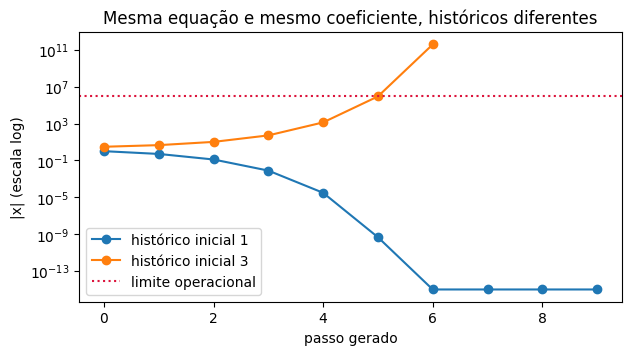

In [2]:
quadratic_steps = 9
quadratic_small = quadratic_path(1.0, np.zeros(quadratic_steps))
quadratic_large = quadratic_path(3.0, np.zeros(quadratic_steps))
quadratic_first_explosion = int(np.flatnonzero(
    np.abs(quadratic_large) >= EXPLOSION_LIMIT
)[0])
assert quadratic_small[-1] < 1e-8
assert quadratic_large[-1] >= EXPLOSION_LIMIT

print("x0=1: primeiros valores", np.round(quadratic_small[:5], 6),
      "| valor final", quadratic_small[-1])
print("x0=3: primeiros valores", np.round(quadratic_large[:5], 6),
      "| primeiro passo >= limite", quadratic_first_explosion)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(np.arange(len(quadratic_small)), np.maximum(abs(quadratic_small), 1e-15),
            "o-", label="histórico inicial 1")
ax.semilogy(np.arange(len(quadratic_large)), abs(quadratic_large),
            "o-", label="histórico inicial 3")
ax.axhline(EXPLOSION_LIMIT, color="crimson", ls=":", label="limite operacional")
ax.set(xlabel="passo gerado", ylabel="|x| (escala log)",
       title="Mesma equação e mesmo coeficiente, históricos diferentes")
ax.legend()
plt.show()

O gráfico executa a mesma recorrência duas vezes. A divergência vem somente da condição inicial; o intervalo usado para sortear o coeficiente não é um limite para os valores que a série poderá atingir.

## 2. Dois coeficientes menores que 1 ainda podem reforçar-se

Agora \(x_{t+1}=0{,}7x_t+0{,}7x_{t-1}\). Cada coeficiente está em \((0,1)\), mas a soma das sensibilidades por lag é \(1{,}4\). Aqui o limite das derivadas é **finito**: o gerador pode preservar a estrutura da árvore e calcular GMC_SCALE, em vez de reamostrar sua estrutura ou seus parâmetros.

Derivadas absolutas por lag: [[0.7, 0.7]]
Soma antes: 1.4 | GMC_SCALE: 0.542857 | soma depois: 0.76
Passo final: bruto = 327.8288 | escalado = 0.010396


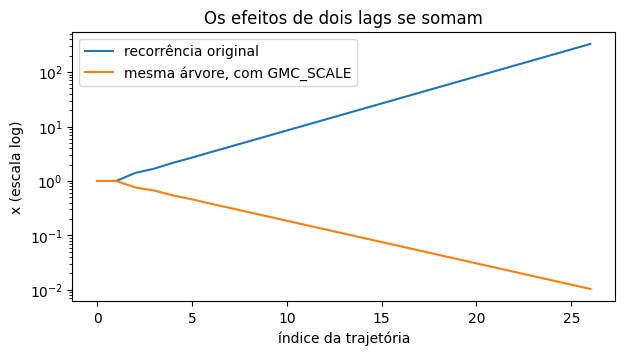

In [3]:
linear_tree = Add(
    Multiply(Parameter("a"), Lag(0, "recent")),
    Multiply(Parameter("b"), Lag(0, "older"))
)
linear_binding = MechanismBinding(
    {"a": 0.7, "b": 0.7}, {"recent": 1, "older": 2}
)
linear_amplitude, linear_derivatives = global_expression_bounds(
    linear_tree, linear_binding, num_series=1, order=2
)
linear_mechanism = build_shao_wu_mechanism(
    (linear_tree,), (linear_binding,),
    ShaoWuConfig(lag_transform="identity", innovation_std=0.05)
)
linear_scale = linear_mechanism.scale
linear_raw = two_lag_path((1, 1), np.zeros(25),
                          lambda recent, older: 0.7 * recent + 0.7 * older)
linear_scaled = two_lag_path((1, 1), np.zeros(25),
                             lambda recent, older: linear_scale * (
                                 0.7 * recent + 0.7 * older))
assert np.allclose(linear_derivatives, [[0.7, 0.7]])
assert linear_mechanism.certificate.holds
assert linear_raw[-1] > 10 * linear_scaled[-1]

print("Derivadas absolutas por lag:", linear_derivatives.tolist())
print("Soma antes:", float(linear_derivatives.sum()),
      "| GMC_SCALE:", round(linear_scale, 6),
      "| soma depois:", round(linear_mechanism.certificate.total_gain, 6))
print("Passo final: bruto =", round(linear_raw[-1], 4),
      "| escalado =", round(linear_scaled[-1], 6))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(linear_raw, label="recorrência original")
ax.semilogy(linear_scaled, label="mesma árvore, com GMC_SCALE")
ax.set(xlabel="índice da trajetória", ylabel="x (escala log)",
       title="Os efeitos de dois lags se somam")
ax.legend()
plt.show()

O código constrói a árvore AST do próprio projeto, calcula seus limites e aplica o fator global. A amplitude global da função linear é infinita, mas as derivadas são finitas: é a sensibilidade, e não a amplitude por si só, que permite escalá-la.

## 3. Produto entre lags: derivada local pequena, limite global infinito

Use \(x_{t+1}=0{,}5x_tx_{t-1}\). As derivadas são \(0{,}5x_{t-1}\) e \(0{,}5x_t\). Perto de zero são pequenas; em todos os possíveis históricos reais, não têm um máximo finito. A comparação usa um histórico pequeno e outro maior, sem ruído. Assim vemos por que derivadas medidas somente nos pontos da série não certificam a equação inteira.

Limites globais das derivadas: [[inf, inf]]
Maior soma das derivadas na trajetória pequena: 0.2
Passo de explosão do histórico (3,3): 7


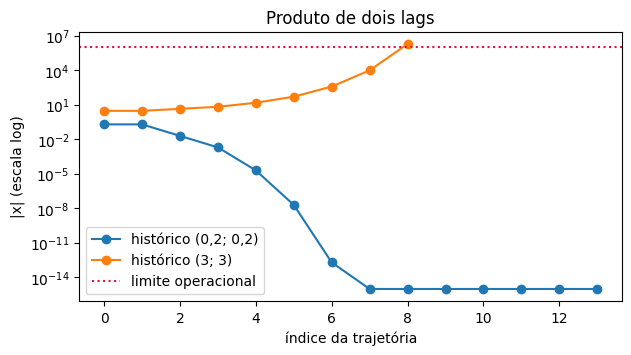

In [4]:
product_tree = Multiply(
    Parameter("a"), Multiply(Lag(0, "recent"), Lag(0, "older"))
)
product_binding = MechanismBinding(
    {"a": 0.5}, {"recent": 1, "older": 2}
)
product_amplitude, product_derivatives = global_expression_bounds(
    product_tree, product_binding, num_series=1, order=2
)
product_clean = two_lag_path((0.2, 0.2), np.zeros(12),
                             lambda recent, older: 0.5 * recent * older)
product_large = two_lag_path((3.0, 3.0), np.zeros(12),
                             lambda recent, older: 0.5 * recent * older)
observed_local_gain = max(
    0.5 * (abs(product_clean[t]) + abs(product_clean[t - 1]))
    for t in range(1, len(product_clean) - 1)
)
assert np.isinf(product_derivatives).all()
assert observed_local_gain < 1
assert product_large[-1] >= EXPLOSION_LIMIT

print("Limites globais das derivadas:", product_derivatives.tolist())
print("Maior soma das derivadas na trajetória pequena:", observed_local_gain)
print("Passo de explosão do histórico (3,3):", len(product_large) - 2)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(np.maximum(abs(product_clean), 1e-15), "o-", label="histórico (0,2; 0,2)")
ax.semilogy(abs(product_large), "o-", label="histórico (3; 3)")
ax.axhline(EXPLOSION_LIMIT, color="crimson", ls=":", label="limite operacional")
ax.set(xlabel="índice da trajetória", ylabel="|x| (escala log)",
       title="Produto de dois lags")
ax.legend()
plt.show()

A AST retorna infinito antes de qualquer simulação. Isso não afirma que a trajetória pequena explodiu: nela, todas as derivadas observadas são pequenas. O limite global examina históricos que essa amostra curta não visitou.

## 4. O histórico inicial limitado não limita o ruído gaussiano

Mesmo começando em \(x_0=0\), a recorrência quadrática pode receber uma inovação grande. Fixamos \(\varepsilon_t\sim\mathcal N(0,0{,}7^2)\) e calculamos a probabilidade exata de um único choque exceder 2,5. Comparamos a probabilidade de **não ver esse choque** em 20 trajetórias de 20 passos com a de 2.000 trajetórias. O caminho com choque explícito é um teste de estresse, não uma amostra representativa; a contagem Monte Carlo registra choques, não explosões.

P(uma inovação >= 2,5): 0.00017751969037347118
P(não observar em 20 x 20 passos): 0.9314486845168247 | observado: 0
P(não observar em 2000 x 20 passos): 0.000823935791235582 | observado: 6
Teste de estresse, primeiros valores: [ 0.      2.5     3.125   4.8828 11.9209 71.0543] | alcançou limite: True


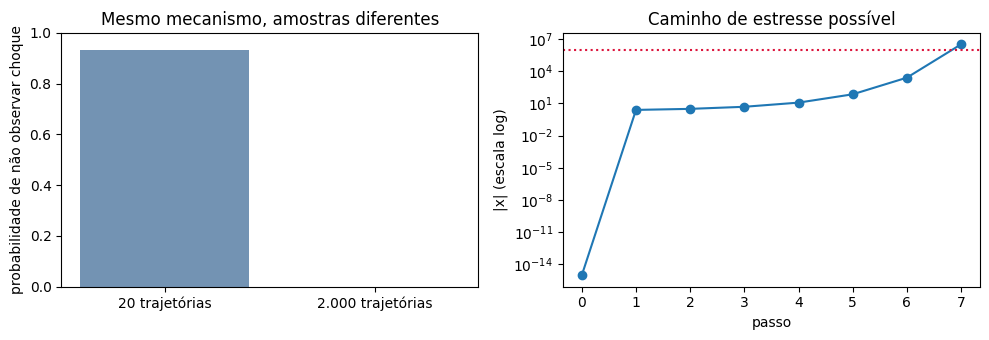

In [5]:
noise_sigma = 0.7
shock_threshold = 2.5
noise_horizon = 20
small_count = 20
large_count = 2000
shock_tail_probability = 0.5 * math.erfc(
    shock_threshold / (noise_sigma * math.sqrt(2))
)
miss_probability_small = (1 - shock_tail_probability) ** (small_count * noise_horizon)
miss_probability_large = (1 - shock_tail_probability) ** (large_count * noise_horizon)
noise_rng = np.random.default_rng(ROOT_SEED)
innovation_matrix = noise_rng.normal(0, noise_sigma, size=(large_count, noise_horizon))
shocks_small = int(np.count_nonzero(
    innovation_matrix[:small_count] >= shock_threshold
))
shocks_large = int(np.count_nonzero(
    innovation_matrix >= shock_threshold
))
stress_innovations = np.zeros(12)
stress_innovations[0] = shock_threshold
stress_path = quadratic_path(0.0, stress_innovations)
assert 0 < shock_tail_probability < 1
assert miss_probability_small > miss_probability_large
assert stress_path[-1] >= EXPLOSION_LIMIT

print("P(uma inovação >= 2,5):", shock_tail_probability)
print("P(não observar em 20 x 20 passos):", miss_probability_small,
      "| observado:", shocks_small)
print("P(não observar em 2000 x 20 passos):", miss_probability_large,
      "| observado:", shocks_large)
print("Teste de estresse, primeiros valores:", np.round(stress_path[:6], 4),
      "| alcançou limite:", bool(stress_path[-1] >= EXPLOSION_LIMIT))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(["20 trajetórias", "2.000 trajetórias"],
            [miss_probability_small, miss_probability_large], color=["#7393B3", "#D77A61"])
axes[0].set(ylabel="probabilidade de não observar choque", ylim=(0, 1),
            title="Mesmo mecanismo, amostras diferentes")
axes[1].semilogy(np.maximum(abs(stress_path), 1e-15), "o-")
axes[1].axhline(EXPLOSION_LIMIT, color="crimson", ls=":")
axes[1].set(xlabel="passo", ylabel="|x| (escala log)",
            title="Caminho de estresse possível")
plt.tight_layout()
plt.show()

A fórmula da cauda gaussiana calcula a chance de *não observar* um choque grande no tamanho de amostra escolhido. A trajetória de estresse mostra o efeito de um choque desse porte seguido de inovações próximas de zero. Isso não estima a taxa total de explosões do processo.

O desvio-padrão 0,7 foi escolhido para tornar visível a cauda em um experimento pequeno. O valor padrão atual do gerador Shao--Wu é 0,05: neste caso, um choque de 2,5 seria muito mais raro. Este exemplo testa a lógica da garantia global sob ruído gaussiano; não mede a frequência de explosões da configuração padrão.

## 5. O outro lado: nosso limite pode rejeitar uma equação contrátil

Considere \(f(x)=0{,}2\tanh(x^2)\). O valor de saída é limitado. Nosso propagador de limites recebe \(\sup|d(x^2)/dx|=\infty\) e usa \(|\tanh'(u)|\leq1\); assim ele ainda devolve um limite de derivada infinito. Porém, a derivada **real da composição** é \(0{,}4x\,\mathrm{sech}^2(x^2)\). Como \(\mathrm{sech}^2(u)\leq4e^{-2u}\) para \(u\geq0\), obtemos \(\sup_x|f'(x)|\leq0{,}8e^{-1/2}<1\). Logo, existe uma prova de contração mais precisa que a regra atual da AST não encontra.

Também calculamos o limite de \(0{,}2\tanh(x)^2\), que é a **equação diferente** obtida quando cada lag do produto é saturado antes da multiplicação.

0,2 tanh(x²): limite do código = [[inf]] | limite matemático <= 0.485225 | máximo na grade = 0.222623 | rejeição do código = True
0,2 tanh(x)²: limite do código = [[0.4]] | certificado = True


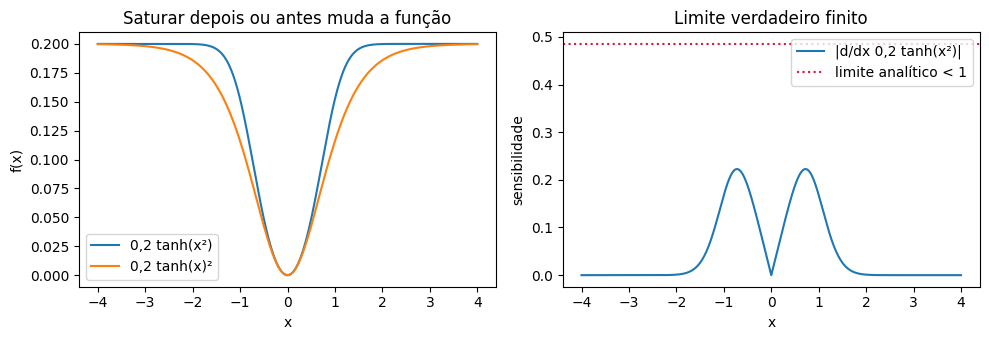

In [6]:
output_saturated_tree = Multiply(
    Parameter("a"), Tanh(Multiply(Lag(0, "lag"), Lag(0, "lag")))
)
input_saturated_tree = Multiply(
    Parameter("a"), Multiply(Tanh(Lag(0, "lag")), Tanh(Lag(0, "lag")))
)
saturated_binding = MechanismBinding({"a": 0.2}, {"lag": 1})
output_amplitude, output_derivatives = global_expression_bounds(
    output_saturated_tree, saturated_binding, num_series=1, order=1
)
input_amplitude, input_derivatives = global_expression_bounds(
    input_saturated_tree, saturated_binding, num_series=1, order=1
)
analytic_lipschitz_bound = 4 * 0.2 * math.exp(-0.5)
grid = np.linspace(-4, 4, 20_001)
actual_output_derivative = 0.4 * grid * (1 - np.tanh(grid ** 2) ** 2)
grid_derivative_max = float(np.abs(actual_output_derivative).max())
try:
    build_shao_wu_mechanism(
        (output_saturated_tree,), (saturated_binding,),
        ShaoWuConfig(lag_transform="identity")
    )
    output_rejected = False
except ValueError as error:
    output_rejected = "finite global derivative bounds" in str(error)
input_mechanism = build_shao_wu_mechanism(
    (input_saturated_tree,), (saturated_binding,),
    ShaoWuConfig(lag_transform="product_lags")
)
assert np.isinf(output_derivatives).all()
assert analytic_lipschitz_bound < 1
assert grid_derivative_max < analytic_lipschitz_bound
assert output_rejected
assert input_mechanism.certificate.holds

print("0,2 tanh(x²): limite do código =", output_derivatives.tolist(),
      "| limite matemático <=", round(analytic_lipschitz_bound, 6),
      "| máximo na grade =", round(grid_derivative_max, 6),
      "| rejeição do código =", output_rejected)
print("0,2 tanh(x)²: limite do código =", input_derivatives.tolist(),
      "| certificado =", input_mechanism.certificate.holds)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(grid, 0.2 * np.tanh(grid ** 2), label="0,2 tanh(x²)")
axes[0].plot(grid, 0.2 * np.tanh(grid) ** 2, label="0,2 tanh(x)²")
axes[0].set(xlabel="x", ylabel="f(x)", title="Saturar depois ou antes muda a função")
axes[0].legend()
axes[1].plot(grid, np.abs(actual_output_derivative), label="|d/dx 0,2 tanh(x²)|")
axes[1].axhline(analytic_lipschitz_bound, color="crimson", ls=":",
                label="limite analítico < 1")
axes[1].set(xlabel="x", ylabel="sensibilidade", title="Limite verdadeiro finito")
axes[1].legend()
plt.tight_layout()
plt.show()

O teste verifica uma limitação do algoritmo de limites, não do teorema: a composição com tanh reduz a derivada verdadeira, mas nossa regra local para a AST perde essa informação. A grade numérica ilustra o resultado; a desigualdade analítica fornece a justificativa global.

## 6. Duas séries: onde a tangente é aplicada no produto?

Partimos da AST \(0{,}5X_tY_t\), com \(X_{t+1}=\varepsilon^X_{t+1}\) e inovação independente \(\varepsilon^Y_{t+1}\) para \(Y\), ambas \(\mathcal N(0,1)\). \(X\) é ruído branco estacionário: tem variância constante, embora admita valores arbitrariamente grandes.

Há **duas transformações distintas** no código. A opção \(\texttt{product\_lags}\), atualmente usada pelo amostrador seletivo, produz \(Y_{t+1}=0{,}5\tanh(X_t)\tanh(Y_t)+\varepsilon^Y_{t+1}\). Seus fatores e derivadas têm limites globais finitos. A função experimental \(\texttt{saturate\_product\_outputs}\) encapsula **a multiplicação inteira**, como \(Y_{t+1}=0{,}5\tanh(X_tY_t)+\varepsilon^Y_{t+1}\). Esta segunda forma expressa literalmente a regra proposta na pergunta, mas ainda não está conectada ao amostrador automático.

Na forma \(\tanh(X_tY_t)\), a linha da Jacobiana de \(Y\) é \(0{,}5\operatorname{sech}^{2}(X_tY_t)(Y_t,X_t)\). Em \(Y_t=0\), a derivada em relação a \(Y_t\) vale \(0{,}5X_t\): seu supremo global é infinito, embora cada avaliação finita seja finita. Mesmo assim, como \(X_t\) é independente do passado de \(Y_t\) e \(\tanh\) é 1-Lipschitz, duas cópias com o mesmo \(X_t\) e ruído obedecem \(\mathbb E(\Delta Y_{t+1})^2\leq 0{,}25\,\mathbb E(\Delta Y_t)^2\). Além disso, \(\mathbb E Y_{t+1}^2\leq 1+0{,}5^2=1{,}25\). Esta é uma aplicação da ideia de contração em momento a \(Y\) quando a série exógena \(X\) é tratada como parte da inovação aleatória; veja [Shao e Wu (2007, Teorema 5.1, pp. 11–12)](https://arxiv.org/pdf/math/0611029#page=11). O verificador bivariado atual, que exige um limite uniforme em ambos os históricos, responde a uma pergunta mais restritiva.

tanh no produto: (0.5 * tanh((x_0(t-1) * x_1(t-1))))
tanh em cada lag: (0.5 * (tanh(x_0(t-1)) * tanh(x_1(t-1))))
Limites por fonte [X, Y] — produto encapsulado: [inf, inf]
Limites por fonte [X, Y] — fatores encapsulados: [0.5, 0.5]
Produto encapsulado rejeitado: True | fatorado certificado: True | escala: 0.95
Variância de Y com tanh(XY): 1.0713 | limite matemático E[Y²] <= 1.25
Variância de Y com tanh(X)tanh(Y): 1.0353
Explosões operacionais [tanh(XY), tanh(X)tanh(Y)]: [0, 0] em 4096 trajetórias
Maior norma Jacobiana observada para tanh(XY): 2.327
Na linha Y=0 e X=1, 10, 1000, 1000000; derivada dY_next/dY: [0.5, 5.0, 500.0, 500000.0]


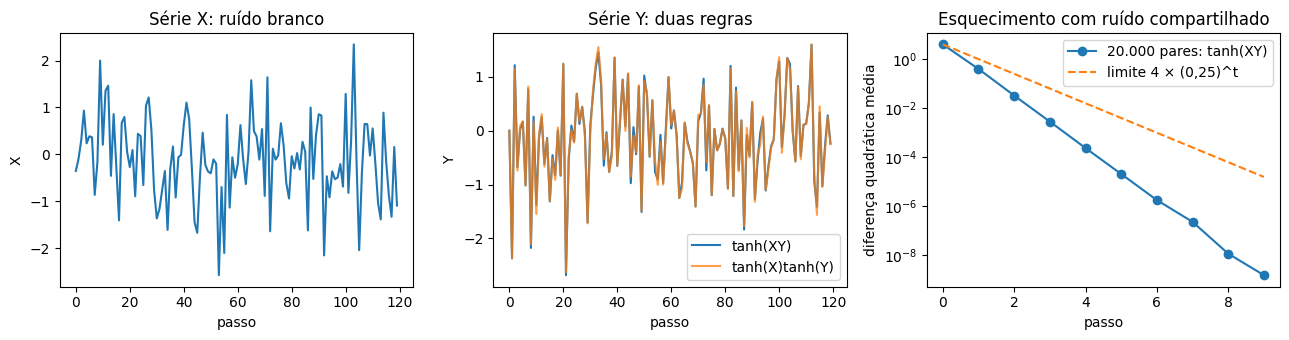

In [7]:
cross_coefficient = 0.5
cross_source_tree = Parameter("zero")
cross_raw_tree = Multiply(
    Parameter("a"), Multiply(Lag(0, "source"), Lag(1, "target"))
)
cross_source_binding = MechanismBinding({"zero": 0.0}, {})
cross_target_binding = MechanismBinding(
    {"a": cross_coefficient}, {"source": 1, "target": 1}
)

# Duas posições diferentes para tanh; nenhuma simulação usa X*Y bruto.
cross_outer_tree = saturate_product_outputs(cross_raw_tree)
cross_inner_tree = saturate_product_lags(cross_raw_tree)
_, cross_outer_derivatives = global_expression_bounds(
    cross_outer_tree, cross_target_binding, num_series=2, order=1
)
_, cross_inner_derivatives = global_expression_bounds(
    cross_inner_tree, cross_target_binding, num_series=2, order=1
)
cross_config = ShaoWuConfig(
    tree_config=RandomTreeConfig(num_series=2, time_probability=0),
    innovation_std=1.0, lag_transform="product_lags"
)
try:
    build_shao_wu_mechanism(
        (cross_source_tree, cross_outer_tree),
        (cross_source_binding, cross_target_binding),
        cross_config
    )
    cross_outer_rejected = False
except ValueError as error:
    cross_outer_rejected = "finite global derivative bounds" in str(error)
cross_inner_mechanism = build_shao_wu_mechanism(
    (cross_source_tree, cross_inner_tree),
    (cross_source_binding, cross_target_binding),
    cross_config
)
cross_inner_scale = cross_inner_mechanism.scale

print("tanh no produto:", to_bound_formula(cross_outer_tree, cross_target_binding))
print("tanh em cada lag:", to_bound_formula(cross_inner_tree, cross_target_binding))
print("Limites por fonte [X, Y] — produto encapsulado:",
      cross_outer_derivatives[:, 0].tolist())
print("Limites por fonte [X, Y] — fatores encapsulados:",
      cross_inner_derivatives[:, 0].tolist())
print("Produto encapsulado rejeitado:", cross_outer_rejected,
      "| fatorado certificado:", cross_inner_mechanism.certificate.holds,
      "| escala:", round(cross_inner_scale, 6))

cross_paths = 4096
cross_steps = 256
cross_initial_discard = 32
cross_rng = np.random.default_rng(ROOT_SEED + 6)
cross_x = cross_rng.normal(size=(cross_paths, cross_steps + 1))
cross_y_noise = cross_rng.normal(size=(cross_paths, cross_steps))
cross_y_outer = np.zeros_like(cross_x)
cross_y_inner = np.zeros_like(cross_x)
for t in range(cross_steps):
    cross_y_outer[:, t + 1] = (
        cross_coefficient * np.tanh(cross_x[:, t] * cross_y_outer[:, t])
        + cross_y_noise[:, t]
    )
    cross_y_inner[:, t + 1] = (
        cross_coefficient * cross_inner_scale
        * np.tanh(cross_x[:, t]) * np.tanh(cross_y_inner[:, t])
        + cross_y_noise[:, t]
    )
cross_outer_variance_upper = 1 + cross_coefficient ** 2
cross_outer_variance_empirical = float(np.var(
    cross_y_outer[:, cross_initial_discard:], ddof=1
))
cross_inner_variance_empirical = float(np.var(
    cross_y_inner[:, cross_initial_discard:], ddof=1
))
cross_outer_explosion_count = int(np.count_nonzero(
    np.any(abs(cross_y_outer) >= EXPLOSION_LIMIT, axis=1)
))
cross_inner_explosion_count = int(np.count_nonzero(
    np.any(abs(cross_y_inner) >= EXPLOSION_LIMIT, axis=1)
))
cross_product = cross_x[:, :-1] * cross_y_outer[:, :-1]
cross_sech2 = 1 - np.tanh(cross_product) ** 2
cross_observed_jacobian_max = float(
    np.max(cross_coefficient * cross_sech2 * np.hypot(
        cross_x[:, :-1], cross_y_outer[:, :-1]
    ))
)

# Mesmo X e mesma inovação futura, apenas o valor inicial de Y muda.
coupling_paths = 20_000
coupling_steps = 9
coupling_rng = np.random.default_rng(ROOT_SEED + 7)
coupling_x = coupling_rng.normal(size=(coupling_paths, coupling_steps))
coupling_y_noise = coupling_rng.normal(size=(coupling_paths, coupling_steps))
coupling_first = np.ones(coupling_paths)
coupling_second = -np.ones(coupling_paths)
coupling_empirical_mse = [4.0]
for t in range(coupling_steps):
    coupling_first = (
        cross_coefficient * np.tanh(coupling_x[:, t] * coupling_first)
        + coupling_y_noise[:, t]
    )
    coupling_second = (
        cross_coefficient * np.tanh(coupling_x[:, t] * coupling_second)
        + coupling_y_noise[:, t]
    )
    coupling_empirical_mse.append(float(np.mean(
        (coupling_first - coupling_second) ** 2
    )))
coupling_theoretical_upper = 4 * (
    cross_coefficient ** 2
) ** np.arange(coupling_steps + 1)

assert np.isinf(cross_outer_derivatives).all()
assert np.isfinite(cross_inner_derivatives).all()
assert cross_outer_rejected
assert cross_inner_mechanism.certificate.holds
assert cross_coefficient ** 2 < 1
assert cross_outer_variance_empirical < cross_outer_variance_upper + 0.1
assert cross_outer_explosion_count == cross_inner_explosion_count == 0
assert coupling_empirical_mse[-1] < coupling_empirical_mse[0]

print("Variância de Y com tanh(XY):", round(cross_outer_variance_empirical, 4),
      "| limite matemático E[Y²] <=", cross_outer_variance_upper)
print("Variância de Y com tanh(X)tanh(Y):", round(cross_inner_variance_empirical, 4))
print("Explosões operacionais [tanh(XY), tanh(X)tanh(Y)]:",
      [cross_outer_explosion_count, cross_inner_explosion_count], "em", cross_paths, "trajetórias")
print("Maior norma Jacobiana observada para tanh(XY):",
      round(cross_observed_jacobian_max, 3))
print("Na linha Y=0 e X=1, 10, 1000, 1000000; derivada dY_next/dY:",
      [cross_coefficient * x for x in (1, 10, 1000, 1_000_000)])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].plot(cross_x[0, :120])
axes[0].set(title="Série X: ruído branco", xlabel="passo", ylabel="X")
axes[1].plot(cross_y_outer[0, :120], label="tanh(XY)")
axes[1].plot(cross_y_inner[0, :120], alpha=0.75, label="tanh(X)tanh(Y)")
axes[1].set(title="Série Y: duas regras", xlabel="passo", ylabel="Y")
axes[1].legend()
axes[2].semilogy(coupling_empirical_mse, "o-", label="20.000 pares: tanh(XY)")
axes[2].semilogy(coupling_theoretical_upper, "--", label="limite 4 × (0,25)^t")
axes[2].set(title="Esquecimento com ruído compartilhado",
            xlabel="passo", ylabel="diferença quadrática média")
axes[2].legend()
plt.tight_layout()
plt.show()

O código parte da mesma AST bruta e aplica as **duas funções existentes** de transformação, imprimindo a fórmula de cada uma antes de gerar as séries. Para \(\tanh(XY)\), nosso limite bivariado é infinito, mas a contração de \(Y\) em média tem fator no máximo \(0{,}25\) no erro quadrático; a curva tracejada é um **limite**, não a trajetória média exata. Para \(\tanh(X)\tanh(Y)\), regra conectada ao amostrador atual, o limite é finito e o certificado passa. O valor \(X=10^6\) é um estado hipotético usado para examinar o supremo, não uma observação da simulação.

## Veredito

Trajetórias observadas e coeficientes individualmente limitados não substituem uma condição matemática quando o objetivo é uma garantia para todos os históricos. Ao mesmo tempo, o teste global uniforme é apenas um caminho suficiente. No caso 6, \(0{,}5\tanh(X_tY_t)\) encapsula o produto e tem limite global de Jacobiana infinito na AST bivariada, mas o alvo \(Y\) contrai em média quando \(X\) é uma inovação exógena independente. Já \(0{,}5\tanh(X_t)\tanh(Y_t)\), que é a transformação do amostrador seletivo atual, tem limite global finito e é certificado. Portanto, **o caso que falha não descreve a regra atualmente conectada ao amostrador**. Se quisermos adotar tanh ao redor do produto inteiro, será uma escolha de geração distinta, a ser registrada e testada separadamente.

Para o benchmark, convém separar: (i) certificado pelo teste global atual; (ii) justificado por outra condição matemática; (iii) comportamento empírico no horizonte testado; (iv) falha operacional observada. Rejeitado pelo teste atual não significa instável.

In [8]:
# EXPERIMENT RECORD — registro completo deste notebook executado
def source_sha256(relative_path):
    return hashlib.sha256((ROOT / relative_path).read_bytes()).hexdigest()

git_head = subprocess.run(
    ["git", "rev-parse", "HEAD"], cwd=ROOT, capture_output=True,
    text=True, check=True
).stdout.strip()
git_dirty = bool(subprocess.run(
    ["git", "status", "--porcelain"], cwd=ROOT, capture_output=True,
    text=True, check=True
).stdout.strip())

record = {
    "research_question": "Coeficientes limitados e trajetórias finitas podem substituir "
                         "a checagem global de sensibilidade?",
    "hypothesis": "Não para uma garantia global; além disso, o limite implementado "
                  "pode ser conservador.",
    "configuration": {
        "quadratic": {"coefficient": 0.5, "histories": [1.0, 3.0],
                      "steps": quadratic_steps},
        "two_lag_linear": {"coefficients": [0.7, 0.7], "initial_history": [1, 1],
                           "steps": 25, "shao_wu_target_gain": 0.8,
                           "safety_factor": 0.95},
        "two_lag_product": {"coefficient": 0.5,
                            "histories": [[0.2, 0.2], [3.0, 3.0]], "steps": 12},
        "gaussian": {"sigma": noise_sigma, "shock_threshold": shock_threshold,
                     "steps_per_trajectory": noise_horizon,
                     "small_trajectory_count": small_count,
                     "large_trajectory_count": large_count,
                     "stress_after_first_shock": "zero"},
        "conservative_bound": {"function": "0.2*tanh(x*x)",
                               "comparison_function": "0.2*tanh(x)**2",
                               "grid_interval": [-4, 4], "grid_points": len(grid)},
        "cross_series": {"source": "iid Gaussian white noise",
                         "outer_product": "Y[t+1]=0.5*tanh(X[t]*Y[t])+epsilon_y[t+1]",
                         "current_product_lags": "Y[t+1]=0.5*s*tanh(X[t])*tanh(Y[t])+epsilon_y[t+1]",
                         "current_product_lags_scale": cross_inner_scale,
                         "innovation_std": 1.0, "paths": cross_paths,
                         "steps": cross_steps,
                         "initial_steps_discarded_for_variance": cross_initial_discard,
                         "coupling_pairs": coupling_paths,
                         "coupling_steps": coupling_steps},
        "explosion_limit": EXPLOSION_LIMIT,
        "noise_distribution": "independent Gaussian in cases 4 and 6"
    },
    "provenance_manifest": {
        "paper": "Shao and Wu (2007), Theorem 5.1, "
                 "https://arxiv.org/pdf/math/0611029#page=11",
        "theory_scope": "Theorem 5.1 applied to Y with iid X as an innovation; "
                        "the implemented bivariate uniform bound is a different check",
        "library_code": {
            "src/tsfmxai/generators/shao_wu.py":
                source_sha256("src/tsfmxai/generators/shao_wu.py"),
            "src/tsfmxai/representations/expression.py":
                source_sha256("src/tsfmxai/representations/expression.py"),
        },
        "repository_head": git_head,
        "working_tree_dirty_at_execution": git_dirty,
        "python": platform.python_version(),
        "numpy": np.__version__,
        "platform": platform.platform(),
        "generated_external_data": False
    },
    "seed_usage": {
        "gaussian_innovations": ROOT_SEED,
        "cross_series_trajectories": ROOT_SEED + 6,
        "cross_series_coupling": ROOT_SEED + 7,
        "deterministic_cases": "cases 1, 2, 3, and 5",
        "stress_path": "explicit innovations, not sampled"
    },
    "metrics": {
        "quadratic_first_explosion_step_from_x0_3": quadratic_first_explosion,
        "quadratic_final_from_x0_1": float(quadratic_small[-1]),
        "two_lag_linear_raw_gain": float(linear_derivatives.sum()),
        "two_lag_linear_scale": float(linear_scale),
        "two_lag_linear_scaled_gain": float(linear_mechanism.certificate.total_gain),
        "two_lag_product_observed_local_gain": float(observed_local_gain),
        "two_lag_product_global_bound_finite": bool(
            np.isfinite(product_derivatives).all()),
        "shock_probability_one_draw": shock_tail_probability,
        "probability_no_shock_small": miss_probability_small,
        "probability_no_shock_large": miss_probability_large,
        "observed_shock_count_small": shocks_small,
        "observed_shock_count_large": shocks_large,
        "output_tanh_code_bound_finite": bool(
            np.isfinite(output_derivatives).all()),
        "output_tanh_analytic_lipschitz_upper_bound": analytic_lipschitz_bound,
        "output_tanh_rejected_by_code": output_rejected,
        "input_tanh_certified_by_code": input_mechanism.certificate.holds,
        "cross_outer_code_bound_finite": bool(
            np.isfinite(cross_outer_derivatives).all()),
        "cross_outer_rejected_by_code": cross_outer_rejected,
        "cross_inner_code_bound_finite": bool(
            np.isfinite(cross_inner_derivatives).all()),
        "cross_inner_certified_by_code": cross_inner_mechanism.certificate.holds,
        "cross_inner_scale": cross_inner_scale,
        "cross_outer_mean_square_contraction_upper": cross_coefficient ** 2,
        "cross_outer_variance_upper": cross_outer_variance_upper,
        "cross_outer_variance_empirical": cross_outer_variance_empirical,
        "cross_inner_variance_empirical": cross_inner_variance_empirical,
        "cross_outer_explosion_count": cross_outer_explosion_count,
        "cross_inner_explosion_count": cross_inner_explosion_count,
        "cross_outer_largest_observed_jacobian": cross_observed_jacobian_max,
        "cross_outer_coupling_mse_upper": coupling_theoretical_upper.tolist(),
        "cross_outer_coupling_mse_empirical": coupling_empirical_mse
    },
    "scientific_summary": (
        "Os casos 1-4 mostram que parâmetros e amostras finitas não fornecem "
        "uma garantia global. O caso 5 mostra uma rejeição conservadora do "
        "algoritmo atual. No caso 6, tanh no produto inteiro falha no limite "
        "uniforme bivariado, mas contrai em média para o alvo. A regra atual "
        "tanh em cada lag possui limite finito e passa no verificador. "
        "Não certificado não significa instável. "
        "A probabilidade de choque mede apenas a amostragem de inovações, "
        "não a taxa de explosões."
    ),
    "reproduction_command_from_repository_root": (
        r".\.venv\Scripts\python.exe -m jupyter nbconvert --to notebook "
        r"--execute --inplace experiments/abstract_syntax_tree/"
        r"global_bounds_vs_observed_paths/00_global_bounds_vs_finite_paths.ipynb "
        r"--ExecutePreprocessor.timeout=120"
    )
}
print(json.dumps(record, ensure_ascii=False, indent=2))

{
  "research_question": "Coeficientes limitados e trajetórias finitas podem substituir a checagem global de sensibilidade?",
  "hypothesis": "Não para uma garantia global; além disso, o limite implementado pode ser conservador.",
  "configuration": {
    "quadratic": {
      "coefficient": 0.5,
      "histories": [
        1.0,
        3.0
      ],
      "steps": 9
    },
    "two_lag_linear": {
      "coefficients": [
        0.7,
        0.7
      ],
      "initial_history": [
        1,
        1
      ],
      "steps": 25,
      "shao_wu_target_gain": 0.8,
      "safety_factor": 0.95
    },
    "two_lag_product": {
      "coefficient": 0.5,
      "histories": [
        [
          0.2,
          0.2
        ],
        [
          3.0,
          3.0
        ]
      ],
      "steps": 12
    },
    "gaussian": {
      "sigma": 0.7,
      "shock_threshold": 2.5,
      "steps_per_trajectory": 20,
      "small_trajectory_count": 20,
      "large_trajectory_count": 2000,
      "stress_af

A célula de registro guarda a configuração completa, sementes, versões, hashes do código consultado, métricas, interpretação e comando de reprodução no próprio notebook executado. Os resultados visuais e numéricos acima permanecem junto do registro.